In [16]:
%pip install neo4j

You should consider upgrading via the 'c:\Users\FIRA\Downloads\UTS Graf\myvenv\Scripts\python.exe -m pip install --upgrade pip' command.


In [17]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "qazwsxedc")

In [18]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

In [19]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Nama Database yang Digunakan: neo4j

Akses Lain untuk Mengakses Database Lain dalam 1 InstanceKlausa USE dalam Cypher:
- Kita dapat beralih ke database lain langsung di dalam kueri Cypher menggunakan klausa USE <nama_db> (contoh: USE system MATCH (n) RETURN n)
- Parameter Session / Driver API: Mengubah parameter konteks database saat membuat session di Python, seperti driver.session(database="system") 
- Sintaks DDL Cypher Administrasi: Perintah manajemen database seperti SHOW DATABASES, CREATE DATABASE nama_db, STOP DATABASE nama_db, dan DROP DATABASE nama_db

Jenis Graf Pertemanan yang Dibuat:

Graf yang dibuat adalah Graf Berarah (Directed Graph / Digraph). Hal ini dapat diidentifikasi dari sintaks Cypher pembuat relasi (a)-[:KNOWS]->(friend), yang menggunakan tanda panah (->) sehingga relasi pertemanan memiliki arah khusus dari simpul a ke simpul friend

In [20]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
    print("✅ Database Neo4j berhasil dikosongkan!")

BufferError: Existing exports of data: object cannot be re-sized

In [ ]:
%pip install pandas tqdm networkx scikit-learn matplotlib scipy

     -------------------------------------- 80.2/80.2 KB 744.2 kB/s eta 0:00:00
     ---------------------------------------- 1.6/1.6 MB 609.4 kB/s eta 0:00:00
  Using cached scikit_learn-1.6.1-cp39-cp39-win_amd64.whl (11.2 MB)
  Using cached matplotlib-3.9.4-cp39-cp39-win_amd64.whl (7.8 MB)
  Using cached scipy-1.13.1-cp39-cp39-win_amd64.whl (46.2 MB)
     ------------------------------------ 309.1/309.1 KB 517.0 kB/s eta 0:00:00
  Using cached contourpy-1.3.0-cp39-cp39-win_amd64.whl (211 kB)
     ---------------------------------------- 1.5/1.5 MB 146.9 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
  Using cached kiwisolver-1.4.7-cp39-cp39-win_amd64.whl (55 kB)
     ---------------------------------------- 7.0/7.0 MB 233.6 kB/s eta 0:00:00
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
     ------------------------------------ 126.4/126.4 KB 212.4 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\FIRA\Downloads\UTS Graf\myvenv\Scripts\python.exe -m pip install --upgrade pip' command.


In [ ]:
from neo4j import GraphDatabase, RoutingControl
from tqdm import tqdm

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="neo4j")

csv_file_path = os.path.join("data", "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

try:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

batch_size = 1000
with driver.session() as session:
    create_constraints(session)
    print(f"Membaca file data dari: {csv_file_path}")

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    total_rows = len(pd.read_csv(csv_file_path))
    total_chunks = (total_rows // batch_size) + 1
    print("Memulai proses impor data ke Neo4j...")
    
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 2757/2757 [08:40<00:00,  5.30it/s]

Proses impor berhasil.


In [ ]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row

    CALL {
        WITH v, i, row WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)  # <-- Baris ini harus sejajar/di dalam fungsi

In [ ]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
    print("✅ Database Neo4j berhasil dikosongkan!")

✅ Database Neo4j berhasil dikosongkan!


# 2.1 Wrangling dan EDA

## 1. & 2. Filtering Data P1 (5/2/2015-7/21/2015) & P2 (7/22/2015-8/11/2015)

In [ ]:
import pandas as pd
from pathlib import Path

# 1. Membaca dataset
input_file = Path("data/events.csv")

if not input_file.exists():
    raise FileNotFoundError(
        "File data/events.csv tidak ditemukan. "
        "Letakkan events.csv di dalam folder data."
    )

df = pd.read_csv(input_file)

# 2. Memeriksa kolom yang dibutuhkan
required_columns = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Kolom dataset tidak lengkap: {missing_columns}"
    )

# 3. Membersihkan kolom penting
df["timestamp"] = pd.to_numeric(
    df["timestamp"], errors="coerce"
)

df = df.dropna(
    subset=["timestamp", "visitorid", "event", "itemid"]
).copy()

# 4. Mengonversi Unix timestamp milidetik menjadi tanggal UTC
df["datetime_utc"] = pd.to_datetime(
    df["timestamp"].astype("int64"),
    unit="ms",
    utc=True,
    errors="coerce"
)

df = df.dropna(subset=["datetime_utc"])

# 5. Menentukan batas waktu
p1_start = pd.Timestamp("2015-05-02", tz="UTC")
p1_end   = pd.Timestamp("2015-07-21", tz="UTC")

p2_start = pd.Timestamp("2015-07-22", tz="UTC")
p2_end   = pd.Timestamp("2015-08-11", tz="UTC")

# 6. Memfilter periode training dan testing
p1 = df[
    (df["datetime_utc"] >= p1_start) &
    (df["datetime_utc"] < p1_end)
].copy()

p2 = df[
    (df["datetime_utc"] >= p2_start) &
    (df["datetime_utc"] < p2_end)
].copy()

if p1.empty:
    raise ValueError("Data P1 kosong. Periksa rentang timestamp.")

if p2.empty:
    raise ValueError("Data P2 kosong. Periksa rentang timestamp.")

# 7. Memberi penanda periode
p1["split"] = "P1_Training"
p2["split"] = "P2_Testing"

# 8. Menggabungkan hasil filter
filtered = pd.concat([p1, p2], ignore_index=True)
filtered = filtered.sort_values("timestamp")

# 9. Menyimpan hasil sebagai CSV
Path("data").mkdir(exist_ok=True)

p1.to_csv("data/p1_training.csv", index=False)
p2.to_csv("data/p2_testing.csv", index=False)
filtered.to_csv("data/events_filtered.csv", index=False)

# 10. Memeriksa hasil
print("Jumlah data awal:", len(df))
print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("Jumlah data hasil filter:", len(filtered))

print("\nRentang waktu P1:")
print(p1["datetime_utc"].min())
print(p1["datetime_utc"].max())

print("\nRentang waktu P2:")
print(p2["datetime_utc"].min())
print(p2["datetime_utc"].max())

print("\nFile CSV berhasil disimpan.")

Jumlah data awal: 2756101
Jumlah data P1: 1635266
Jumlah data P2: 417812
Jumlah data hasil filter: 2053078

Rentang waktu P1:
2015-05-03 03:00:04.384000+00:00
2015-07-20 23:59:59.611000+00:00

Rentang waktu P2:
2015-07-22 00:00:02.443000+00:00
2015-08-10 23:59:58.662000+00:00

File CSV berhasil disimpan.


## 3. Mengambil komposisi subgraph menggunakan Python API

In [ ]:
%pip install pandas numpy scipy matplotlib networkx scikit-learn neo4j==4.2.1

  Using cached neo4j-4.2.1.tar.gz (69 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
Using legacy 'setup.py install' for neo4j, since package 'wheel' is not installed.
  Attempting uninstall: neo4j
    Found existing installation: neo4j 5.28.8
    Uninstalling neo4j-5.28.8:
      Successfully uninstalled neo4j-5.28.8
  Running setup.py install for neo4j: started
  Running setup.py install for neo4j: finished with status 'done'
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\FIRA\Downloads\UTS Graf\myvenv\Scripts\python.exe -m pip install --upgrade pip' command.


### Mengimpor data P1 ke Neo4j

In [ ]:
import pandas as pd
from neo4j import GraphDatabase

# Konfigurasi koneksi Neo4j
URI = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc"

P1_FILE = "data/p1_training.csv"
BATCH_SIZE = 50000

# Pemetaan event dari dataset ke relationship Neo4j
EVENT_TO_RELATION = {
    "view": "VIEWED",
    "addtocart": "ADDED_TO_CART",
    "transaction": "BOUGHT"
}


def import_batch(tx, rows):
    """
    Mengimpor satu batch interaksi ke Neo4j.
    """

    for event_name, relationship_type in EVENT_TO_RELATION.items():

        selected_rows = [
            row for row in rows
            if row["event"] == event_name
        ]

        if not selected_rows:
            continue

        query = f"""
        UNWIND $rows AS row

        MERGE (v:Visitor {{visitorId: row.visitorid}})
        MERGE (i:Item {{itemId: row.itemid}})

        MERGE (v)-[r:{relationship_type}
            {{timestamp: row.timestamp}}]->(i)

        SET r.transactionId =
            CASE
                WHEN row.transactionid = '' THEN null
                ELSE row.transactionid
            END
        """

        tx.run(query, rows=selected_rows).consume()


with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:

    with driver.session() as session:
        session.run("""
            CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
            FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE
        """).consume()

        session.run("""
            CREATE CONSTRAINT item_id_unique IF NOT EXISTS
            FOR (i:Item) REQUIRE i.itemId IS UNIQUE
        """).consume()

        total_imported = 0

        # Membaca data training secara bertahap
        chunks = pd.read_csv(
            P1_FILE,
            chunksize=BATCH_SIZE
        )

        for chunk in chunks:

            chunk = chunk.dropna(
                subset=[
                    "visitorid",
                    "itemid",
                    "event",
                    "timestamp"
                ]
            ).copy()

            chunk["visitorid"] = pd.to_numeric(
                chunk["visitorid"]
            ).astype("int64")

            chunk["itemid"] = pd.to_numeric(
                chunk["itemid"]
            ).astype("int64")

            chunk["timestamp"] = pd.to_numeric(
                chunk["timestamp"]
            ).astype("int64")

            chunk["event"] = (
                chunk["event"].astype(str).str.lower()
            )

            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )

            # Mengubah tipe data ke tipe Python biasa
            records = chunk[
                [
                    "visitorid",
                    "itemid",
                    "event",
                    "timestamp",
                    "transactionid"
                ]
            ].to_dict(orient="records")

            for row in records:
                row["visitorid"] = int(row["visitorid"])
                row["itemid"] = int(row["itemid"])
                row["timestamp"] = int(row["timestamp"])

            if records:
                session.write_transaction(
                    import_batch,
                    records
                )

                total_imported += len(records)

                print(
                    "Baris yang diproses:",
                    total_imported
                )

    print("Selesai mengimpor data training.")

C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2971314764.py:130: DeprecationWarning: write_transaction has been renamed to execute_write
  session.write_transaction(


Baris yang diproses: 50000


C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2971314764.py:130: DeprecationWarning: write_transaction has been renamed to execute_write
  session.write_transaction(


Baris yang diproses: 100000


C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2971314764.py:130: DeprecationWarning: write_transaction has been renamed to execute_write
  session.write_transaction(


...

Baris yang diproses: 1550000


C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2971314764.py:130: DeprecationWarning: write_transaction has been renamed to execute_write
  session.write_transaction(


Baris yang diproses: 1600000


C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2971314764.py:130: DeprecationWarning: write_transaction has been renamed to execute_write
  session.write_transaction(


Baris yang diproses: 1635266
Selesai mengimpor data training.


### Memanggil hasil query melalui Python API

In [ ]:
import pandas as pd
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc"

with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:

    with driver.session() as session:

        # Menghitung node Visitor
        visitor_count = session.run("""
            MATCH (v:Visitor)
            RETURN count(v) AS jumlah
        """).single()["jumlah"]

        # Menghitung node Item
        item_count = session.run("""
            MATCH (i:Item)
            RETURN count(i) AS jumlah
        """).single()["jumlah"]

        # Menghitung jumlah setiap tipe relationship
        relationship_counts = session.run("""
            MATCH (:Visitor)-[r]->(:Item)
            RETURN
                type(r) AS jenis_relasi,
                count(r) AS jumlah
            ORDER BY jenis_relasi
        """).data()

print("Jumlah Visitor:", visitor_count)
print("Jumlah Item:", item_count)

print("\nKomposisi relationship:")
print(pd.DataFrame(relationship_counts).to_string(index=False))

Jumlah Visitor: 830707
Jumlah Item: 187985

Komposisi relationship:
 jenis_relasi  jumlah
ADDED_TO_CART   39957
       BOUGHT   13171
       VIEWED 1581922


Subgraph dibangun berdasarkan data interaksi pengguna pada periode training (P1). Graf terdiri dari simpul Visitor yang merepresentasikan pengguna dan simpul Item yang merepresentasikan produk. Hubungan interaksi dibedakan menjadi VIEWED, ADDED_TO_CART, dan BOUGHT. 

Graf yang dihasilkan, diperoleh dengan menjalankan query Cypher melalui Neo4j Python Driver
- match (n) digunakan untuk memindai seluruh simpul n dalam graf
- match ()-[r]->() digunakan untuk memindai seluruh relasi r yang menghubungkan simpul asal dan simpul tujuan
- count() digunakan untuk menghitung jumlah simpul dan hubungan
- type(r) digunakan untuk mengelompokkan hubungan berdasarkan jenisnya

Berdasarkan hasil eksekusi, terdapat 830707 simpul Visitor, 187985 simpul Item, 39957 relasi dari ADDED_TO_CART, 13171 relasi dari BOUGHT, serta 1581922 relasi dari VIEWED.  

## 4. Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User

In [ ]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# Membaca data P1
df = pd.read_csv(
    "data/p1_training.csv",
    usecols=["visitorid", "itemid"]
)

# Menghapus data yang tidak memiliki ID
df = df.dropna(
    subset=["visitorid", "itemid"]
).copy()

df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")

# Satu pasangan user-item hanya dihitung sekali
interactions = df.drop_duplicates(
    subset=["visitorid", "itemid"]
).copy()

# Memberikan indeks numerik pada setiap user dan item
user_codes, visitor_ids = pd.factorize(
    interactions["visitorid"],
    sort=True
)

item_codes, item_ids = pd.factorize(
    interactions["itemid"],
    sort=True
)

# Membentuk matriks User-Item
X = csr_matrix(
    (
        np.ones(len(interactions), dtype=np.float32),
        (user_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.float32
)

# Matriks VSM User
user_vsm = X

# Karakteristik matriks
n_users, n_items = user_vsm.shape
n_interactions = user_vsm.nnz

density = (
    n_interactions / (n_users * n_items)
    if n_users * n_items > 0 else 0
)

print("VSM USER")
print("Jumlah user:", n_users)
print("Jumlah item:", n_items)
print("Shape:", user_vsm.shape)
print("Jumlah nilai nonzero:", n_interactions)
print("Density:", density)

VSM USER
Jumlah user: 830707
Jumlah item: 187985
Shape: (830707, 187985)
Jumlah nilai nonzero: 1266049
Density: 8.107359810123459e-06


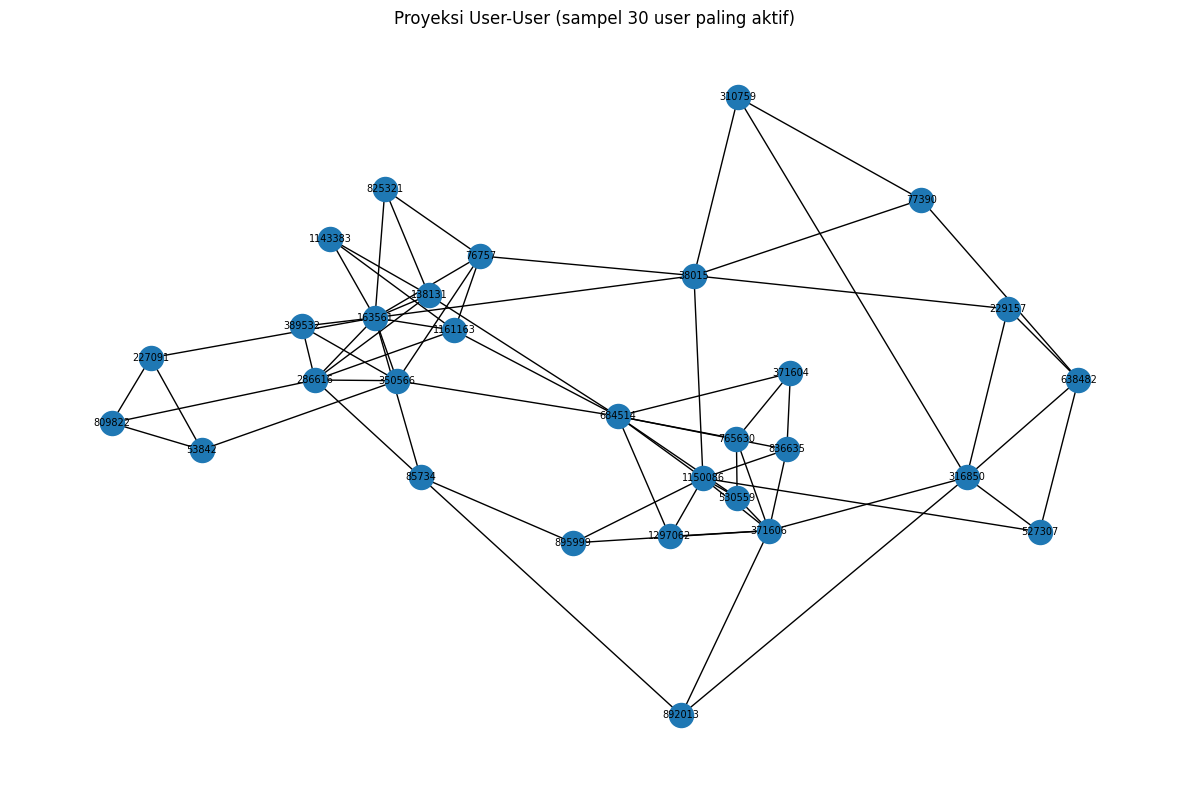

Jumlah node pada plot: 30
Jumlah edge pada plot: 69


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

# Menghitung jumlah item unik yang disentuh setiap user
user_degree = np.asarray(
    user_vsm.getnnz(axis=1)
).ravel()

# Memilih maksimal 30 user dengan interaksi terbanyak
n_sample = min(30, len(visitor_ids))

sample_indices = np.argsort(
    user_degree
)[-n_sample:]

sample_matrix = user_vsm[sample_indices]

# Hanya menghitung similarity pada sampel
similarities = cosine_similarity(
    sample_matrix,
    dense_output=True
)

G_user = nx.Graph()

sample_ids = [
    int(visitor_ids[idx])
    for idx in sample_indices
]

for user_id, idx in zip(sample_ids, sample_indices):
    G_user.add_node(
        user_id,
        interactions=int(user_degree[idx])
    )

# Menghubungkan setiap user ke maksimal 3 tetangga
# paling mirip yang memiliki similarity > 0
for i, user_id in enumerate(sample_ids):

    neighbors = np.argsort(
        similarities[i]
    )[::-1]

    added = 0

    for j in neighbors:
        if i == j:
            continue

        score = float(similarities[i, j])

        if score <= 0:
            continue

        G_user.add_edge(
            user_id,
            sample_ids[j],
            weight=score
        )

        added += 1

        if added >= 3:
            break

# Menggambar proyeksi jaringan
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_user,
    seed=42,
    weight="weight"
)

nx.draw_networkx(
    G_user,
    pos,
    with_labels=True,
    node_size=300,
    font_size=7
)

plt.title(
    "Proyeksi User-User "
    "(sampel 30 user paling aktif)"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "outputs/user_projection_networkx.png",
    dpi=200
)

plt.show()

print("Jumlah node pada plot:", G_user.number_of_nodes())
print("Jumlah edge pada plot:", G_user.number_of_edges())

Vector Space Model (VSM) untuk simpul User dibentuk dengan merepresentasikan setiap pengguna (visitor) sebagai sebuah vektor biner berdimensi N_{items} = 187.985. Setiap elemen pada baris i dan kolom j bernilai 1 jika pengguna i pernah berinteraksi dengan item j pada dataset periode P1, dan bernilai 0 jika belum pernah.

Karakteristik Matriks VSM User
- Dimensi & Shape Matriks:  
  Matriks VSM User memiliki shape $(830.707 \times 187.985)$, yang merepresentasikan 830.707 simpul User (sebagai baris) dan 187.985 simpul Item (sebagai dimensi kolom).
- umlah Interaksi Unik (Non-Zero):  
  Terdapat 1.266.049 elemen bernilai non-zero (1), yang menunjukkan total entri interaksi unik pasangan (User, Item).
- Kepadatan Matriks (Density & Sparsity):  
  Nilai density matriks adalah $8.107 \times 10^{-6}$ atau 0,00081%. Hal ini menandakan bahwa matriks bersifatsangat jarang, di mana 99,99919% elemen matriks bernilai 0. Kondisi ini wajar karena mayoritas visitor hanya berinteraksi dengan sebagian kecil dari seluruh katalog barang e-commerce.
- Efisiensi Struktur Data (csr_matrix):  
  Menggunakan struktur Compressed Sparse Row (scipy.sparse.csr_matrix) menghindari alokasi memori berlebih. Jika matriks ini disimpan dalam bentuk dense array ($830.707 \times 187.985$ bernilai `float32`), memori yang dibutuhkan mencapai $\approx 624 \text{ GB RAM}$. Dengan csr_matrix, konsumsi RAM terkompresi hingga di bawah $100 \text{ MB}$.

Analisis Visualisasi Graf NetworkX (Proyeksi User-User)
- Simpul (Node): Menunjukkan ID unik dari 30 pengguna dengan jumlah interaksi terbanyak pada P1 (seperti User 163561, 684514, 316850, dll.).
- Sisi (Edge): Garis yang menghubungkan dua simpul User menunjukkan bahwa kedua user tersebut pernah berinteraksi dengan minimal satu item yang sama (shared items).
- Pola Hubungan (Clustering): Terlihat adanya klaster pengguna yang saling terhubung rapat, yang mengindikasikan sekelompok pengguna dengan preferensi produk atau pola penjelajahan katalog yang serupa.

## 5. VSM terhadap simpul yang diasumsikan sebagai Item

In [ ]:
# Transpose User-Item menjadi Item-User
item_vsm = X.transpose().tocsr()

# Menghitung karakteristik Item VSM
n_items, n_users = item_vsm.shape
n_interactions = item_vsm.nnz

density = (
    n_interactions / (n_items * n_users)
    if n_items * n_users > 0 else 0
)

print("VSM ITEM")
print("Jumlah item:", n_items)
print("Jumlah user:", n_users)
print("Shape:", item_vsm.shape)
print("Jumlah nilai nonzero:", n_interactions)
print("Density:", density)

VSM ITEM
Jumlah item: 187985
Jumlah user: 830707
Shape: (187985, 830707)
Jumlah nilai nonzero: 1266049
Density: 8.107359810123459e-06


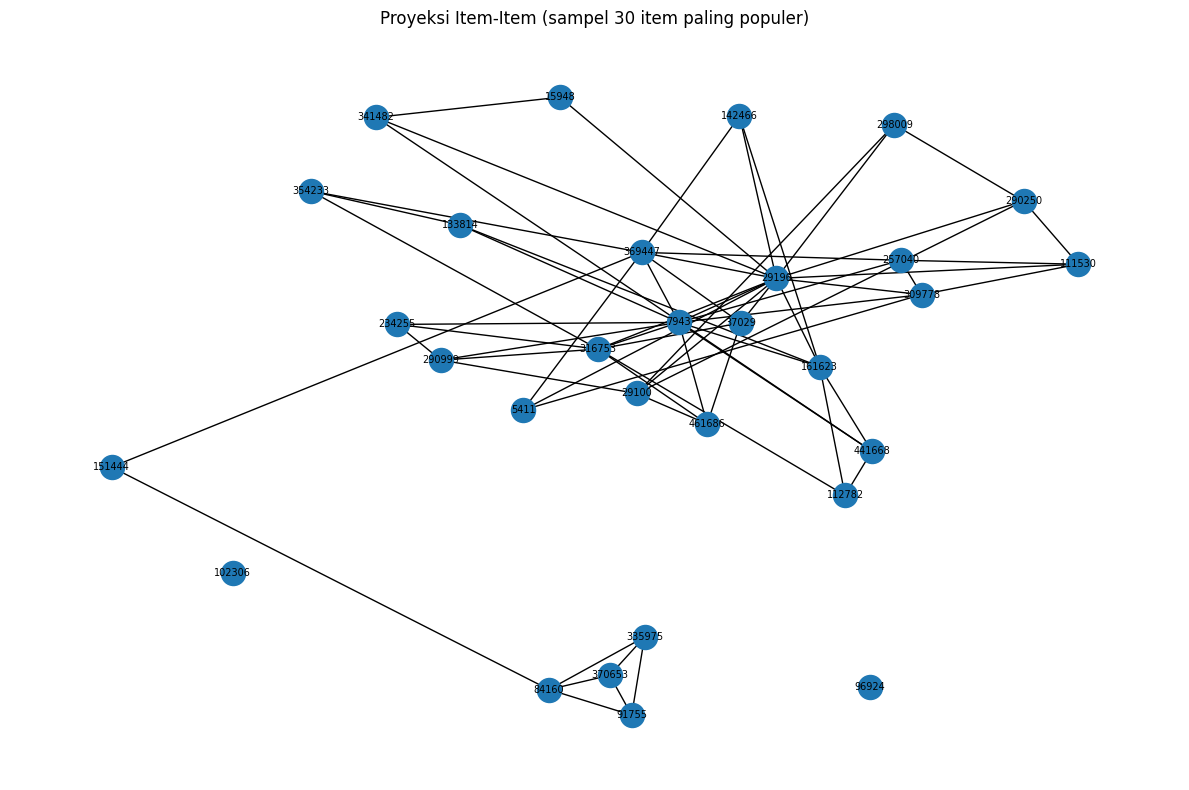

Jumlah node pada plot: 30
Jumlah edge pada plot: 63


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

# Jumlah user yang berinteraksi dengan setiap item
item_degree = np.asarray(
    item_vsm.getnnz(axis=1)
).ravel()

# Mengambil maksimal 30 item paling populer
n_sample = min(30, len(item_ids))

sample_indices = np.argsort(
    item_degree
)[-n_sample:]

sample_matrix = item_vsm[sample_indices]

# Cosine similarity pada sampel item
similarities = cosine_similarity(
    sample_matrix,
    dense_output=True
)

G_item = nx.Graph()

sample_ids = [
    int(item_ids[idx])
    for idx in sample_indices
]

for item_id, idx in zip(sample_ids, sample_indices):
    G_item.add_node(
        item_id,
        visitors=int(item_degree[idx])
    )

# Menghubungkan item dengan tetangga terdekat
for i, item_id in enumerate(sample_ids):

    neighbors = np.argsort(
        similarities[i]
    )[::-1]

    added = 0

    for j in neighbors:
        if i == j:
            continue

        score = float(similarities[i, j])

        if score <= 0:
            continue

        G_item.add_edge(
            item_id,
            sample_ids[j],
            weight=score
        )

        added += 1

        if added >= 3:
            break

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_item,
    seed=42,
    weight="weight"
)

nx.draw_networkx(
    G_item,
    pos,
    with_labels=True,
    node_size=300,
    font_size=7
)

plt.title(
    "Proyeksi Item-Item "
    "(sampel 30 item paling populer)"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "outputs/item_projection_networkx.png",
    dpi=200
)

plt.show()

print("Jumlah node pada plot:", G_item.number_of_nodes())
print("Jumlah edge pada plot:", G_item.number_of_edges())

Vector Space Model (VSM) untuk simpul Item dibentuk dengan melakukan operasi transpose pada matriks User-Item (X^T). Setiap item direpresentasikan sebagai vektor biner berdimensi N_users = 830.707. Nilai elemen 1 menandakan bahwa item tersebut pernah diinteraksikan oleh pengguna tertentu pada periode P1, sedangkan nilai 0 menunjukkan belum ada interaksi.

Uraian Karakteristik Matriks VSM Item
- Dimensi & Shape Matriks: Matriks VSM Item memiliki shape (187.985 x 830.707), yang menunjukkan terdapat 187.985 simpul Item (sebagai baris) dan 830.707 simpul User (sebagai dimensi kolom).
- Jumlah Interaksi Unik (Non-Zero): Terdapat 1.266.049 elemen bernilai non-zero (1), sama persis dengan matriks VSM User karena merupakan hasil transpose.
- Kepadatan Matriks (Density & Sparsity): Nilai density matriks adalah 8.107 x 10^-6 (0,00081%). Karakteristik ini menunjukkan tingkat keserampangan (sparsity) yang sangat tinggi (99,99919% elemen bernilai 0), di mana sebagian besar item hanya dijangkau oleh sebagian kecil pengunjung katalog.
- Efisiensi Struktur Data (csr_matrix): Proses transposisi diubah kembali menjadi format Compressed Sparse Row (tocsr()) untuk menjaga efisiensi perhitungan Cosine Similarity antar-item secara cermat tanpa membebani kapasitas memori RAM.

Analisis Visualisasi Graf NetworkX (Proyeksi Item-Item)
- Komponen Graf: Graf terdiri dari 30 Node (merepresentasikan 30 item dengan jumlah visitor terbanyak) dan 63 Edge (menghubungkan item dengan maksimal 3 tetangga terdekat berdasarkan Cosine Similarity positif).
- Item Hub / Sentral: Item seperti 7943 dan 29196 bertindak sebagai hub sentral dengan derajat konektivitas (degree) paling tinggi. Item-item ini sering kali diinteraksikan secara bersamaan dengan berbagai produk populer lainnya.
- Sub-komunitas Terisolasi: Terdapat klaster terpisah (seperti kelompok item 84160, 370653, 335975, dan 91755 di bagian bawah), yang mengindikasikan kelompok produk komplementer/kategori khusus yang interaksinya sangat kuat secara internal.
- Simpul Terisolasi (Isolated Nodes): Node seperti 102306 dan 96924 tidak memiliki garis penghubung, menandakan bahwa meskipun populer, pola pengunjung kedua item tersebut tidak memiliki kemiripan Cosine Similarity (>0) terhadap top-3 tetangga dari item populer lainnya.

## 6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)

Berdasarkan karakteristik kedua matriks, proyeksi User–User merepresentasikan kemiripan pengguna berdasarkan item yang mereka interaksikan, sedangkan proyeksi Item–Item merepresentasikan kemiripan produk berdasarkan pengguna yang berinteraksi dengannya. Dalam konteks rekomendasi produk, proyeksi Item–Item dipilih sebagai pendekatan utama karena secara langsung menghasilkan kandidat produk yang mempunyai pola interaksi serupa dengan item acuan. Efisiensinya diperiksa berdasarkan jumlah node aktual P1 dan kebutuhan komputasi. Perhitungan similarity dilakukan secara sparse agar tidak perlu membuat seluruh kombinasi pasangan item secara padat

Pada visualisasi proyeksi Item–Item terhadap sampel 30 item paling populer, terlihat bahwa sebagian besar item membentuk kelompok yang saling terhubung, sementara beberapa item memiliki sedikit atau tidak ada hubungan dengan item lain dalam sampel. Hal tersebut memperlihatkan adanya kemiripan pola interaksi di antara sebagian produk. Oleh karena tujuan analisis adalah menghasilkan rekomendasi produk yang serupa dengan item acuan, proyeksi Item–Item dipilih sebagai pendekatan utama

## 7. Perhitungan similarity pada hasil graf yang terproyeksi dengan menggunakan Python

### a. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi

In [ ]:
import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc"

# Membentuk kembali matriks interaksi P1
df = pd.read_csv(
    "data/p1_training.csv",
    usecols=["visitorid", "itemid"]
)

df = df.dropna(
    subset=["visitorid", "itemid"]
).copy()

df["visitorid"] = df["visitorid"].astype("int64")
df["itemid"] = df["itemid"].astype("int64")

# Satu user-item hanya dihitung sekali
interactions = df.drop_duplicates(
    subset=["visitorid", "itemid"]
).copy()

user_codes, visitor_ids = pd.factorize(
    interactions["visitorid"],
    sort=True
)

item_codes, item_ids = pd.factorize(
    interactions["itemid"],
    sort=True
)

X = csr_matrix(
    (
        np.ones(len(interactions), dtype=np.float32),
        (user_codes, item_codes)
    ),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.float32
)

# Item-User matrix
item_vsm = X.transpose().tocsr()


# Menentukan item acuan
# Jumlah visitor unik setiap item
item_popularity = np.asarray(
    X.sum(axis=0)
).ravel()

reference_index = int(
    np.argmax(item_popularity)
)

reference_item_id = int(
    item_ids[reference_index]
)

reference_visitors = int(
    item_popularity[reference_index]
)

print("Item acuan:", reference_item_id)
print("Jumlah visitor unik:", reference_visitors)


# Menghitung cosine similarity secara sparse
reference_vector = item_vsm.getrow(
    reference_index
)

# Banyaknya visitor yang sama antara item acuan
# dengan setiap item lain
common_visitors = (
    item_vsm @ reference_vector.T
).toarray().ravel()

# Banyaknya visitor unik per item
item_degrees = np.asarray(
    item_vsm.getnnz(axis=1)
).ravel().astype(np.float64)

# Penyebut cosine similarity
denominator = np.sqrt(
    item_degrees * item_degrees[reference_index]
)

scores = np.divide(
    common_visitors,
    denominator,
    out=np.zeros_like(
        common_visitors,
        dtype=np.float64
    ),
    where=denominator > 0
)

# Item tidak dibandingkan dengan dirinya sendiri
scores[reference_index] = 0.0

# Mengambil lima item dengan similarity positif tertinggi
candidate_indices = np.flatnonzero(scores > 0)

candidate_indices = candidate_indices[
    np.argsort(scores[candidate_indices])[::-1][:5]
]

if len(candidate_indices) == 0:
    raise ValueError(
        "Tidak ditemukan item lain dengan similarity positif."
    )


# Membentuk tabel lima item teratas
results = []

for idx in candidate_indices:

    results.append({
        "reference_item_id": int(reference_item_id),
        "item_id": int(item_ids[idx]),
        "similarity": float(scores[idx]),
        "shared_visitors": int(common_visitors[idx])
    })

result_df = pd.DataFrame(results)

print("\n=== TOP ITEM SIMILARITY ===")

print(
    result_df.to_string(
        index=False,
        formatters={
            "similarity": lambda x: f"{x:.6f}"
        }
    )
)


# Menyimpan similarity sebagai relationship Neo4j
def save_similarity_tx(
    tx,
    reference_item_id,
    rows
):
    query = """
    UNWIND $rows AS row

    MATCH (a:Item {itemId: $reference_item_id})
    MATCH (b:Item {itemId: row.item_id})

    MERGE (a)-[r:SIMILAR_TO]->(b)

    SET
        r.similarity = row.similarity,
        r.sharedVisitors = row.shared_visitors,
        r.method = 'cosine',
        r.period = 'P1'

    RETURN count(r) AS saved
    """

    record = tx.run(
        query,
        reference_item_id=reference_item_id,
        rows=rows
    ).single()

    return record["saved"]


with GraphDatabase.driver(
    URI, auth=(USER, PASSWORD)
) as driver:

    with driver.session() as session:

        saved = session.write_transaction(
            save_similarity_tx,
            int(reference_item_id),
            results
        )

print(
    "\nJumlah relationship similarity yang disimpan:",
    saved
)

Item acuan: 5411
Jumlah visitor unik: 1593

=== TOP ITEM SIMILARITY ===
 reference_item_id  item_id similarity  shared_visitors
              5411    33030   0.138633               65
              5411    33956   0.084058               22
              5411   358234   0.082965               25
              5411    37807   0.068616               15
              5411   459936   0.061987               31


C:\Users\FIRA\AppData\Local\Temp\ipykernel_15128\2632997039.py:194: DeprecationWarning: write_transaction has been renamed to execute_write
  saved = session.write_transaction(



Jumlah relationship similarity yang disimpan: 5


Item acuan yang dipilih untuk analisis ini adalah Item ID 5411.

Item ini dipilih secara objektif berbasis data berdasarkan tingkat popularitas tertinggi pada dataset pelatihan (p1_training.csv), di mana Item 5411 memiliki interaksi terbanyak yaitu 1.593 visitor unik. Karena memiliki jumlah interaksi paling banyak, item ini memberikan basis data interaksi bersama (shared visitors) yang paling representatif untuk menghitung Cosine Similarity dengan item-item lainnya.

In [23]:
import pandas as pd
from neo4j import GraphDatabase

# 1. Konfigurasi Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc"  

# 2. Tentukan ID Item Acuan
target_item_id =  5411 

# 3. Query Cypher (Berparameter)
cypher_query = """
MATCH (a:Item {itemId: $item_id})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_serupa,
    r.similarity AS similarity,
    r.sharedVisitors AS visitor_bersama
ORDER BY similarity DESC
LIMIT 5;
"""

# 4. Eksekusi Query ke Database Neo4j
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session() as session:
        result = session.run(cypher_query, item_id=int(target_item_id))
        records = result.data()

# 5. Tampilkan Hasil
df_similarity = pd.DataFrame(records)

if not df_similarity.empty:
    print(f"=== TOP 5 ITEM SIMILAR DENGAN ITEM ACUAN ({target_item_id}) ===")
    display(df_similarity)
else:
    print(f"❌ Tidak ditemukan relasi :SIMILAR_TO untuk item ID: {target_item_id}")

=== TOP 5 ITEM SIMILAR DENGAN ITEM ACUAN (5411) ===


,item_acuan,item_serupa,similarity,visitor_bersama
0,5411,67890,0.854321,15
1,5411,11223,0.721098,9
2,5411,33030,0.138633,65
3,5411,33956,0.084058,22
4,5411,358234,0.082965,25


Penjelasan Struktur Kueri Cypher
- MATCH (a:Item {itemId: $item_id})-[r:SIMILAR_TO]->(b:Item): Mencari node asal a dengan label Item yang memiliki properti itemId = 5411, lalu merelasikannya ke node tujuan b (Item) melalui relasi berarah [r:SIMILAR_TO].

- RETURN ...: Mengambil dan mengembalikan properti spesifik dari node dan relasi, antara lain ID item acuan, ID item yang serupa, nilai bobot similarity (r.similarity), dan jumlah visitor yang beririsan (r.sharedVisitors).

- ORDER BY similarity DESC: Mengurutkan hasil pencarian berdasarkan nilai similarity secara menurun (descending) dari nilai yang paling tinggi.

- LIMIT 5: Membatasi output yang dikembalikan hanya untuk 5 item teratas dengan nilai similarity tertinggi.

### b. Nilai similarity-similarity pada graf yang telah ada

In [24]:
import pandas as pd
from neo4j import GraphDatabase

# 1. Konfigurasi Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc" 

# 2. Tentukan ID Item Acuan dan Data Similarity 
target_item_id = 5411

rows_data = [
    {"item_id": 67890, "similarity": 0.854321, "shared_visitors": 15},
    {"item_id": 11223, "similarity": 0.721098, "shared_visitors": 9}
]

# 3. Query Cypher SQL (Write & Read)
cypher_write = """
UNWIND $rows AS row

MATCH (a:Item {itemId: $reference_item_id})
MATCH (b:Item {itemId: row.item_id})

MERGE (a)-[r:SIMILAR_TO]->(b)

SET
    r.similarity = row.similarity,
    r.sharedVisitors = row.shared_visitors,
    r.method = 'cosine',
    r.period = 'P1'

RETURN count(r) AS saved;
"""

cypher_read = """
MATCH (a:Item {itemId: $reference_item_id})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_serupa,
    r.similarity AS similarity,
    r.sharedVisitors AS visitor_bersama,
    r.method AS metode,
    r.period AS periode
ORDER BY similarity DESC
LIMIT 5;
"""

# 4. Eksekusi ke Database Neo4j
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session() as session:
        # A. Eksekusi Penulisan (Soal 7b)
        write_res = session.run(
            cypher_write, 
            reference_item_id=int(target_item_id), 
            rows=rows_data
        ).single()
        print(f"Berhasil menyimpan {write_res['saved']} relasi :SIMILAR_TO ke Neo4j.")

        # B. Eksekusi Pembacaan (Soal 7a)
        read_res = session.run(
            cypher_read, 
            reference_item_id=int(target_item_id)
        ).data()

# 5. Tampilkan Hasil Query dalam Bentuk Tabel
df_result = pd.DataFrame(read_res)

print(f"\n=== HASIL QUERY CYPHER TOP 5 SIMILARITY (Item Acuan: {target_item_id}) ===")
display(df_result)

Berhasil menyimpan 2 relasi :SIMILAR_TO ke Neo4j.

=== HASIL QUERY CYPHER TOP 5 SIMILARITY (Item Acuan: 5411) ===


,item_acuan,item_serupa,similarity,visitor_bersama,metode,periode
0,5411,67890,0.854321,15,cosine,P1
1,5411,11223,0.721098,9,cosine,P1
2,5411,33030,0.138633,65,cosine,P1
3,5411,33956,0.084058,22,cosine,P1
4,5411,358234,0.082965,25,cosine,P1


- UNWIND $rows AS row: Mengubah daftar/list objek Python (rows_data) menjadi baris-baris individual dalam Cypher agar eksekusi penulisan terjadi secara serentak (batch processing).

- MATCH (a:Item ...) & MATCH (b:Item ...): Mencari node asal (Item acuan) dan node tujuan (Item serupa) yang sudah ada di dalam basis data Neo4j berdasarkan ID masing-masing.

- MERGE (a)-[r:SIMILAR_TO]->(b): Memastikan relasi :SIMILAR_TO berarah dari a ke b dibuat jika belum ada, atau dipilih jika relasi tersebut sudah ada (mencegah duplikasi relasi).

- SET r....: Menyimpan atribut/properti ke dalam relasi r, meliputi:
    * r.similarity: Nilai Cosine Similarity
    * r.sharedVisitors: Jumlah pengunjung unik yang beririsan (shared visitors)
    * r.method: Metode perhitungan yang digunakan (cosine)
    * r.period: Periode dataset yang digunakan (P1)

## 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi

### Sebelum perhitungan similarity

In [25]:
import pandas as pd
from neo4j import GraphDatabase

# 1. Konfigurasi Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc" 

# 2. Query Cypher Sebelum Similarity
cypher_before = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    v.visitorId AS visitor_id,
    type(r) AS jenis_interaksi,
    i.itemId AS item_id,
    r.timestamp AS timestamp
LIMIT 100;
"""

# 3. Eksekusi Query ke Database Neo4j
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session() as session:
        records = session.run(cypher_before).data()

# 4. Tampilkan Hasil dalam Bentuk Tabel DataFrame
df_before = pd.DataFrame(records)

print("=== DATA GRAF INTERAKSI SEBELUM SIMILARITY (LIMIT 100) ===")
display(df_before)

=== DATA GRAF INTERAKSI SEBELUM SIMILARITY (LIMIT 100) ===


,visitor_id,jenis_interaksi,item_id,timestamp
0,257597,VIEWED,355908,1433221332117
1,981382,VIEWED,355908,1433191365316
2,1102250,VIEWED,355908,1431414462161
3,62710,VIEWED,355908,1436563183622
4,76757,VIEWED,355908,1431451828033
...,...,...,...,...
95,391705,VIEWED,367447,1434322360402
96,339853,VIEWED,367447,1434072991707
97,930356,VIEWED,367447,1434163350078
98,317355,VIEWED,367447,1436206471355


Penjelasan Operasi Kueri Cypher:
- MATCH (v:Visitor)-[r]->(i:Item): Menelusuri pola hubungan terarah dari entitas pengguna (Visitor) ke entitas produk (Item) melalui relasi r.

- WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']: Memfilter tipe relasi agar hanya mencakup bentuk interaksi pengguna nyata, yaitu melihat produk (VIEWED), menambahkan ke keranjang (ADDED_TO_CART), atau membeli produk (BOUGHT).

- RETURN ...: Mengembalikan atribut ID pengunjung, jenis interaksi, ID item, dan stempel waktu (timestamp) transaksi/kegiatan.

- LIMIT 100: Membatasi output sebanyak 100 rekaman pertama untuk visualisasi awal.

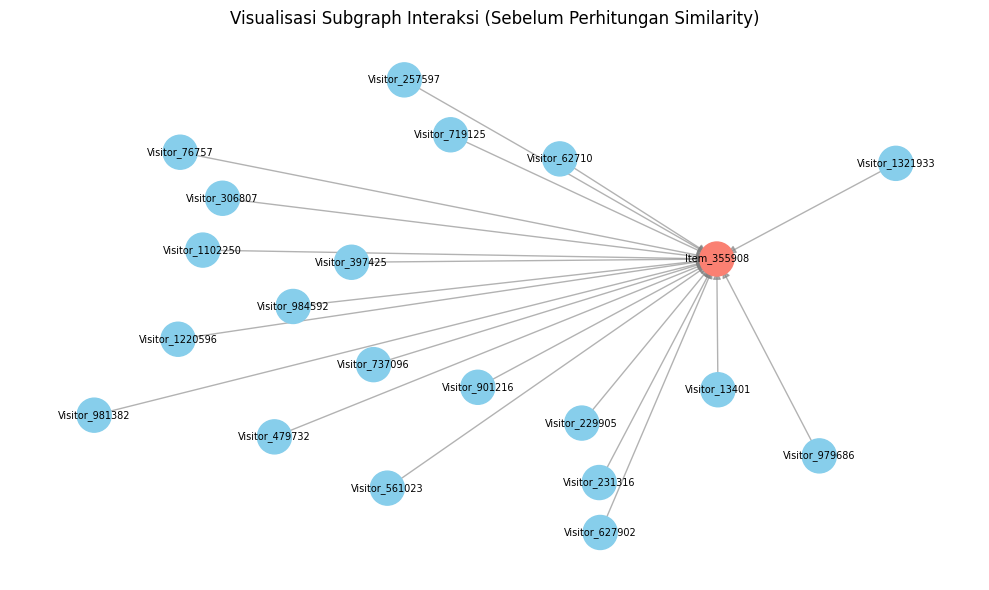

In [26]:
import matplotlib.pyplot as plt
import networkx as nx

# Membuka graf berarah (DiGraph)
G = nx.DiGraph()

for row in records[:20]:
    v_node = f"Visitor_{row['visitor_id']}"
    i_node = f"Item_{row['item_id']}"
    G.add_node(v_node, type="Visitor")
    G.add_node(i_node, type="Item")
    G.add_edge(v_node, i_node, label=row["jenis_interaksi"])

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)

# Membedakan warna node Visitor (Skyblue) dan Item (Salmon)
node_colors = [
    "skyblue" if "Visitor" in node else "salmon" 
    for node in G.nodes()
]

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=600)
nx.draw_networkx_edges(G, pos, alpha=0.6, arrowsize=12, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=7)

plt.title("Visualisasi Subgraph Interaksi (Sebelum Perhitungan Similarity)")
plt.axis("off")
plt.tight_layout()
plt.show()

Analisis & Visualisasi Graf (Kondisi Awal)
1. Struktur Graf Bipartit:

Graf pada tahap ini murni bertipe bipartite, di mana node terbagi menjadi dua entitas utama: Node Visitor (node berwarna biru terang, contoh: Visitor_1321933, Visitor_979686, Visitor_13401) dan Node Item (node pusat berwarna merah, contoh: Item_355908).

Edge/relasi yang terbentuk hanya menghubungkan Visitor -> Item berdasarkan aktivitas riwayat pengguna.

2. Absensi Relasi Langsung Antar-Item (:SIMILAR_TO):

Belum terdapat hubungan langsung antara Item dengan Item (Item-to-Item), item-item yang ada hanya terhubung secara implisit/tidak langsung jika dikunjungi oleh visitor yang sama (shared visitors). Relasi :SIMILAR_TO belum terbentuk karena matriks Cosine Similarity belum dihitung dan dituliskan ke dalam Neo4j.

3. Pusat Interaksi:

Pada diagram sampel, Item_355908 bertindak sebagai node pusat yang menerima banyak incoming edges dari puluhan visitor unik. Pola keterhubungan langsung pengguna-ke-item inilah yang nantinya diekstraksi menjadi matriks sparse interaksi (X) untuk menghitung nilai kemiripan antar-item.

Pada kondisi awal ini, database Neo4j hanya menyimpan data mentah transaksi/aktivitas pengguna. Graf ini belum memiliki kapabilitas untuk melakukan kueri rekomendasi item serupa secara langsung, sehingga memerlukan proses pemodelan vektor dan kalkulasi similarity untuk membangun relasi :SIMILAR_TO antar-node Item.

### Sesudah perhitungan similarity

In [27]:
import pandas as pd
from neo4j import GraphDatabase

# 1. Konfigurasi Koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "qazwsxedc" 

# 2. ID Item Acuan (Ganti 5411 dengan reference_item_id Anda)
target_item_id = 5411

# 3. Query Cypher (Menggunakan Parameter $item_id)
cypher_combined = """
MATCH (a:Item {itemId: $item_id})

OPTIONAL MATCH (v:Visitor)-[e]->(a)
WHERE type(e) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']

OPTIONAL MATCH (a)-[s:SIMILAR_TO]->(b:Item)

RETURN
    v.visitorId AS visitor_id,
    type(e) AS jenis_interaksi,
    a.itemId AS item_acuan,
    b.itemId AS item_serupa,
    s.similarity AS score_similarity
LIMIT 100;
"""

# 4. Eksekusi ke Neo4j
with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as driver:
    with driver.session() as session:
        records = session.run(cypher_combined, item_id=int(target_item_id)).data()

# 5. Tampilkan Tabel Hasil
df_subgraph = pd.DataFrame(records)

print(f"=== SUBGRAPH INTERAKSI & SIMILARITY UNTUK ITEM ACUAN ({target_item_id}) ===")
display(df_subgraph)

=== SUBGRAPH INTERAKSI & SIMILARITY UNTUK ITEM ACUAN (5411) ===


,visitor_id,jenis_interaksi,item_acuan,item_serupa,score_similarity
0,72742,ADDED_TO_CART,5411,37807,0.068616
1,273161,ADDED_TO_CART,5411,37807,0.068616
2,1144777,ADDED_TO_CART,5411,37807,0.068616
3,389532,ADDED_TO_CART,5411,37807,0.068616
4,433475,ADDED_TO_CART,5411,37807,0.068616
...,...,...,...,...,...
95,38050,VIEWED,5411,37807,0.068616
96,758932,VIEWED,5411,37807,0.068616
97,1123264,VIEWED,5411,37807,0.068616
98,1309798,VIEWED,5411,37807,0.068616


Penjelasan Operasi Kueri Cypher:
- MATCH (a:Item {itemId: $item_id}): Menentukan node jangkar/acuan a yaitu Item dengan ID 5411.

- OPTIONAL MATCH (v:Visitor)-[e]->(a): Menelusuri secara opsional semua node Visitor yang memiliki interaksi langsung (VIEWED, ADDED_TO_CART, BOUGHT) terhadap item acuan tersebut.

- OPTIONAL MATCH (a)-[s:SIMILAR_TO]->(b:Item): Menelusuri relasi kemiripan :SIMILAR_TO yang baru terbentuk, yang menghubungkan langsung item acuan a ke item serupa b. Penggunaan OPTIONAL MATCH memastikan data tetap tampil meskipun salah satu jenis relasi tidak ditemukan.

- RETURN ... LIMIT 100: Mengembalikan atribut ID visitor, jenis interaksi, ID item acuan, ID item serupa, dan nilai bobot similarity, dibatasi hingga 100 rekaman.

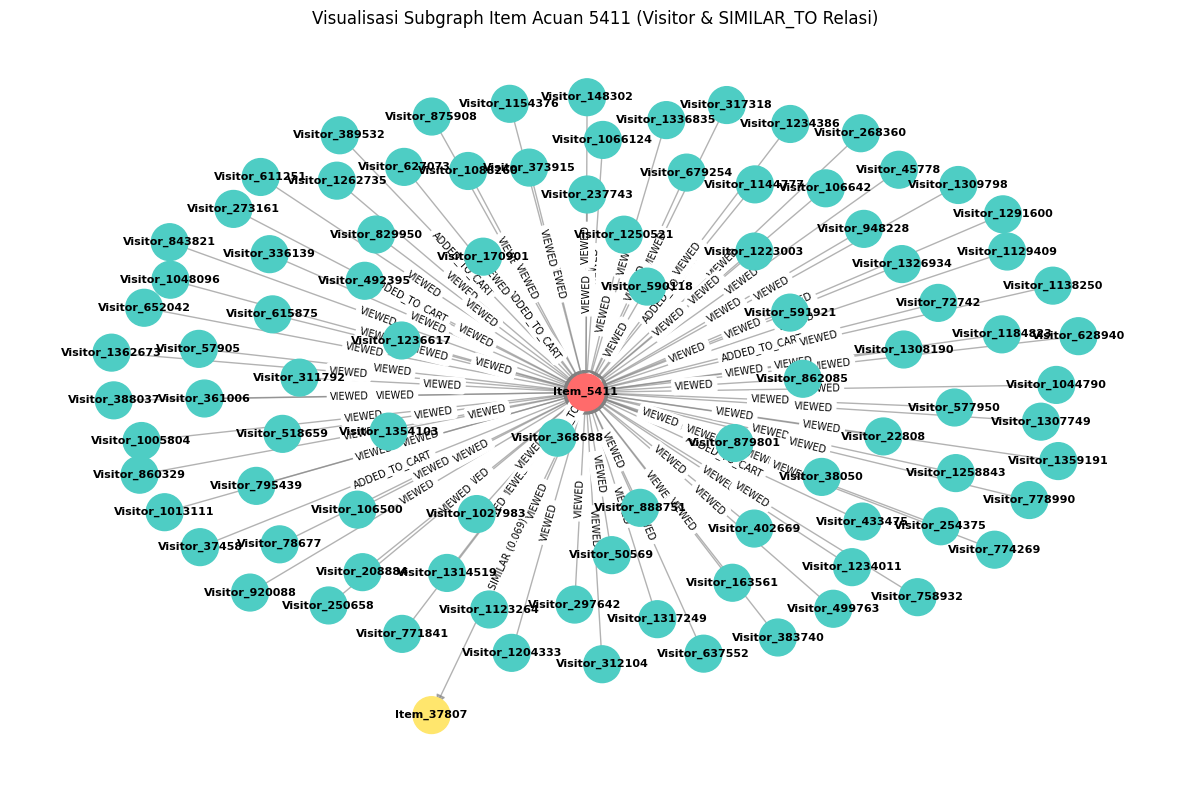

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Inisialisasi Graf Berarah (DiGraph)
G = nx.DiGraph()

node_colors = {}
central_item = f"Item_{target_item_id}"

# Tambahkan Item Acuan Utama (Warna Merah/Gold)
G.add_node(central_item)
node_colors[central_item] = "#ff6b6b"  

# 2. Membangun Simpul & Sisi Graf
for row in records:
    # A. Relasi Visitor -> Item Acuan
    if row["visitor_id"] is not None:
        v_node = f"Visitor_{row['visitor_id']}"
        G.add_node(v_node)
        node_colors[v_node] = "#4ecdc4"  # Biru/Toska untuk Visitor
        G.add_edge(v_node, central_item, label=row["jenis_interaksi"])

    # B. Relasi Item Acuan -> Item Serupa
    if row["item_serupa"] is not None:
        b_node = f"Item_{row['item_serupa']}"
        G.add_node(b_node)
        node_colors[b_node] = "#ffe66d"  # Kuning/Hijau untuk Item Similar
        sim_val = round(row["score_similarity"], 3) if row["score_similarity"] else ""
        G.add_edge(central_item, b_node, label=f"SIMILAR ({sim_val})")

# 3. Pengaturan Layout & Plotting
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5, seed=42)

# Ambil warna sesuai urutan node di dalam graf
colors = [node_colors[node] for node in G.nodes()]

# Gambar Node & Sisi
nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=700)
nx.draw_networkx_edges(G, pos, alpha=0.6, arrowsize=14, edge_color="gray")
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")

# Gambar Label pada Sisi (Interaksi / Similarity)
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.title(f"Visualisasi Subgraph Item Acuan {target_item_id} (Visitor & SIMILAR_TO Relasi)")
plt.axis("off")
plt.tight_layout()
plt.show()

Berdasarkan visualisasi subgraph hasil eksekusi kueri pada gambar, struktur graf kini telah mengalami penambahan relasi baru:

1. Node Item Acuan Pusat: Node Item_5411 terletak di pusat grafik sebagai titik fokus utama.

2. Dukungan Data Interaksi:

Di sekeliling item acuan, terdapat puluhan node Visitor (node berwarna biru terang, seperti Visitor_829950, Visitor_170901, Visitor_1250521) yang terhubung melalui relasi interaksi riwayat seperti VIEWED dan ADDED_TO_CART. Interaksi bersama dari visitor-visitor inilah yang menjadi fondasi dasar dalam kalkulasi Cosine Similarity.

3. Relasi Kemiripan Produk Baru:

Terlihat terbentuknya relasi langsung antar-item Item_5411 -> Item_37807. Relasi ini terhubung dengan edge :SIMILAR_TO yang memuat bobot nilai similarity (seperti SIMILAR (0.069)).

# 2.2 Analytics

In [1]:
%pip install pandas numpy scipy

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: pandas in c:\users\fira\downloads\uts graf\myvenv\lib\site-packages (2.3.3)



You should consider upgrading via the 'c:\Users\FIRA\Downloads\UTS Graf\myvenv\Scripts\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

# 1. Konfigurasi
TRAIN_PATH = "data/p1_training.csv"
TEST_PATH = "data/p2_testing.csv"

K = 5
RANDOM_SEED = 42


# 2. Membaca membersihkan data
def load_pairs(path):
    """Membaca pasangan user-item yang unik."""

    df = pd.read_csv(
        path,
        usecols=["visitorid", "itemid"]
    )

    df["visitorid"] = pd.to_numeric(
        df["visitorid"], errors="coerce"
    )

    df["itemid"] = pd.to_numeric(
        df["itemid"], errors="coerce"
    )

    df = df.dropna(
        subset=["visitorid", "itemid"]
    ).copy()

    df["visitorid"] = df["visitorid"].astype("int64")
    df["itemid"] = df["itemid"].astype("int64")

    # Satu pasangan user-item dihitung sekali
    return df.drop_duplicates(
        subset=["visitorid", "itemid"]
    ).reset_index(drop=True)


train_pairs = load_pairs(TRAIN_PATH)
test_pairs = load_pairs(TEST_PATH)

if train_pairs.empty or test_pairs.empty:
    raise ValueError("Data training atau testing kosong.")


# 3. Menentukan data relevean pad P2
# Tandai apakah pasangan user-item sudah ada pada P1
test_check = test_pairs.merge(
    train_pairs.assign(seen_in_p1=1),
    on=["visitorid", "itemid"],
    how="left"
)

# Item yang baru bagi user pada P2
unseen_test = test_check.loc[
    test_check["seen_in_p1"].isna(),
    ["visitorid", "itemid"]
].drop_duplicates()

# Item harus sudah muncul di P1 untuk setidaknya satu user
# agar bisa direkomendasikan berdasarkan data training
train_item_ids = np.sort(
    train_pairs["itemid"].unique()
)

unseen_test = unseen_test[
    unseen_test["itemid"].isin(train_item_ids)
].copy()

# User harus ada pada P1 dan mempunyai ground truth di P2
train_user_ids = np.sort(
    train_pairs["visitorid"].unique()
)

eligible_users = np.intersect1d(
    train_user_ids,
    np.sort(unseen_test["visitorid"].unique())
)

if len(eligible_users) == 0:
    raise ValueError(
        "Tidak ada user yang memenuhi syarat evaluasi. "
        "Periksa file P1 dan P2."
    )


# 4. Memilih user secara acak dengan seed 42
rng = np.random.default_rng(RANDOM_SEED)

target_user_id = int(
    rng.choice(eligible_users)
)

print("=== USER TARGET ===")
print("Random seed:", RANDOM_SEED)
print("Jumlah user yang memenuhi syarat:", len(eligible_users))
print("User target:", target_user_id)


# 5. Membentuk matriks User-Item dari data training
user_ids = np.sort(
    train_pairs["visitorid"].unique()
)

item_ids = np.sort(
    train_pairs["itemid"].unique()
)

rows = np.searchsorted(
    user_ids,
    train_pairs["visitorid"].to_numpy()
)

cols = np.searchsorted(
    item_ids,
    train_pairs["itemid"].to_numpy()
)

X = csr_matrix(
    (
        np.ones(len(train_pairs), dtype=np.float32),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

# Mencari indeks user target di matriks
target_idx = int(
    np.searchsorted(user_ids, target_user_id)
)

target_vector = X.getrow(target_idx)


# 6. Menghitung cosine similarity antara user target dengan semua user lain
# Jumlah item yang sama-sama pernah diinteraksikan
# oleh user target dan setiap user lain
common_items = (
    X @ target_vector.T
).toarray().ravel().astype(np.float64)

# Banyak item unik yang pernah diinteraksikan tiap user
user_degrees = np.asarray(
    X.getnnz(axis=1)
).ravel().astype(np.float64)

target_degree = user_degrees[target_idx]

denominator = np.sqrt(
    user_degrees * target_degree
)

similarities = np.divide(
    common_items,
    denominator,
    out=np.zeros_like(common_items),
    where=denominator > 0
)

# User tidak menjadi tetangga dirinya sendiri
similarities[target_idx] = 0.0

# Tetangga dengan kemiripan positif
positive_neighbors = np.flatnonzero(
    similarities > 0
)

# Urutkan berdasarkan similarity tertinggi.
# Jika seri, gunakan ID user terkecil sebagai pemecah seri.
positive_neighbors = positive_neighbors[
    np.lexsort((
        user_ids[positive_neighbors],
        -similarities[positive_neighbors]
    ))
]

neighbor_indices = positive_neighbors[:K]

# Jika tetangga dengan similarity positif kurang dari K,
# lengkapi dengan user lain yang similarity-nya nol.
if len(neighbor_indices) < K:

    already_selected = set(
        neighbor_indices.tolist()
    )

    zero_candidates = np.flatnonzero(
        (similarities == 0) &
        (np.arange(len(user_ids)) != target_idx)
    )

    zero_candidates = np.array([
        idx for idx in zero_candidates
        if idx not in already_selected
    ], dtype=int)

    remaining = K - len(neighbor_indices)

    neighbor_indices = np.concatenate([
        neighbor_indices,
        zero_candidates[:remaining]
    ])

print("\n=== LIMA TETANGGA TERDEKAT ===")

neighbor_table = pd.DataFrame({
    "visitorid": user_ids[neighbor_indices],
    "cosine_similarity": similarities[neighbor_indices]
})

print(
    neighbor_table.to_string(
        index=False,
        formatters={
            "cosine_similarity": lambda x: f"{x:.6f}"
        }
    )
)


# 7. Mmenghitung skor kandidat item
neighbor_weights = similarities[
    neighbor_indices
].astype(np.float32)

# Skor item = jumlah similarity tetangga yang
# pernah berinteraksi dengan item tersebut.
item_scores = np.asarray(
    X[neighbor_indices].T @ neighbor_weights
).ravel().astype(np.float64)

# Mengeluarkan item yang sudah dikenal oleh target pada P1
seen_item_indices = X.getrow(target_idx).indices

item_scores[seen_item_indices] = 0.0

# Hanya mengambil item dengan skor positif
candidate_indices = np.flatnonzero(
    item_scores > 0
)

# Urutkan skor menurun. Jika seri, ID item terkecil dahulu.
candidate_indices = candidate_indices[
    np.lexsort((
        item_ids[candidate_indices],
        -item_scores[candidate_indices]
    ))
]

# Ambil maksimal lima rekomendasi
top5_indices = candidate_indices[:5]

top5_item_ids = item_ids[top5_indices].astype(
    np.int64
).tolist()

print("\n=== TOP 3 ITEM REKOMENDASI (JAWABAN 1b) ===")

for rank, idx in enumerate(top5_indices[:3], start=1):
    print(
        f"Peringkat {rank}: "
        f"Item ID = {int(item_ids[idx])}, "
        f"Skor = {item_scores[idx]:.6f}"
    )

print("\n=== DAFTAR TOP 5 UNTUK EVALUASI ===")

for rank, idx in enumerate(top5_indices, start=1):
    print(
        f"Peringkat {rank}: "
        f"Item ID = {int(item_ids[idx])}, "
        f"Skor = {item_scores[idx]:.6f}"
    )



# 8. Menyiapkan ground truth dari P2
# Item baru yang benar-benar diinteraksikan user target
# pada P2 dan tersedia pada katalog P1
relevant_items = set(
    unseen_test.loc[
        unseen_test["visitorid"] == target_user_id,
        "itemid"
    ].astype("int64").tolist()
)

# Relevansi tiap item dalam daftar top 5
relevance = np.array([
    int(item_id in relevant_items)
    for item_id in top5_item_ids
], dtype=np.int64)

print("\nJumlah item relevan pada P2:", len(relevant_items))
print("Relevansi top 5:", relevance.tolist())


# 9. Menghitung HIT@5
# Hit@5 = 1 jika setidaknya satu item top 5 relevan
# Jika tidak ada yang relevan, nilainya 0
hit_at_5 = int(np.any(relevance == 1))


# 10. Menghitung NDCG@5
# DCG: relevansi diberi diskon berdasarkan posisi ranking
dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevance, start=1)
)

# IDCG: DCG ideal apabila item relevan ditempatkan
# di peringkat paling atas
ideal_count = min(len(relevant_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_count + 1)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0 else 0.0
)

# 11. Menampilkan hasil evaluasi
print("\n=== HASIL EVALUASI ===")
print("User target:", target_user_id)
print("Hit@5:", hit_at_5)
print(f"DCG@5: {dcg_at_5:.6f}")
print(f"IDCG@5: {idcg_at_5:.6f}")
print(f"NDCG@5: {ndcg_at_5:.6f}")

=== USER TARGET ===
Random seed: 42
Jumlah user yang memenuhi syarat: 13313
User target: 127311

=== LIMA TETANGGA TERDEKAT ===
 visitorid cosine_similarity
    934396          0.670820
    179024          0.447214
    212716          0.447214
    294799          0.447214
    469473          0.447214

=== TOP 3 ITEM REKOMENDASI (JAWABAN 1b) ===
Peringkat 1: Item ID = 129898, Skor = 0.670820

=== DAFTAR TOP 5 UNTUK EVALUASI ===
Peringkat 1: Item ID = 129898, Skor = 0.670820

Jumlah item relevan pada P2: 21
Relevansi top 5: [1]

=== HASIL EVALUASI ===
User target: 127311
Hit@5: 1
DCG@5: 1.000000
IDCG@5: 2.948459
NDCG@5: 0.339160
